<a href="https://colab.research.google.com/github/matthewhflin/matthewhflin-AnalyticsEngineering/blob/main/2_03_practice_bike_hire_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=17M9oGaOj4KdKiDDH3oTibxJ9qBTSjp6n)

# 2.03 Practice session
## Bike-hire trips

## How this practice works

This is a **short rehearsal** of the timed test. You do not need to finish or get the "right" answer. The aim is to practise the way of working.

- You have about **45 minutes**. Work individually.
- You may use **any AI tool** (for example Gemini in Colab). We are **not marking** anything today. In the real test, the quality of AI-generated code will not matter. What matters is the control youDshow.
- Write in markdown cells as you go: your thinking, **each prompt you send (paste it as you send it)**, and the checks you make.
- Unfinished work is fine. Say what you did not get to.
- At the end, download the Notebook (using File > Download > Download .ipynb). Once it has completed please zip the file up. This is the artefact you would submit for the in-class test.
- You can also save a copy to your GitHub using the instructions from my.wbs (1b asychronous tasks).

**Suggested timing**

| Minutes | Focus |
| --- | --- |
| 0 to 10 | Look at the tables and note what you find |
| 10 to 25 | Clean and prepare the data |
| 25 to 38 | Join and aggregate to answer the question |
| 38 to 45 | Check your answer and write up |

At the end, use **Runtime, then Restart session and run all** and note anything that fails.


## The data

A fictional bike-hire scheme: three tables covering trips taken in March 2025.

| Table | What it holds |
| --- | --- |
| `trips` | One record per trip: bike, start and end station, start time, duration and user type |
| `bikes` | The bikes, with type and purchase year |
| `stations` | The docking stations, with zone and capacity |

**How they connect:** `trips.bike_id` to `bikes.bike_id`, and `trips.start_station_id` (and `end_station_id`) to `stations.station_id`.

Check the real column names in the next cell before you write anything.


In [1]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os

import duckdb
import pandas as pd

DATA_URL = "https://github.com/MJMortensonWarwick/adminaeaiv/releases/download/dbsession/bike-hire-practice.zip"

DATA_DIR = "/content/bikes"
# Download only if no CSV files are there yet. The CSVs may sit inside a folder
# within the zip; the search below looks in sub-folders too.
if DATA_URL and not glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True):
    import urllib.request
    import zipfile
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, "/content/bikes.zip")
    zipfile.ZipFile("/content/bikes.zip").extractall(DATA_DIR)

FILES = {"trips": "trips.csv", "bikes": "bikes.csv", "stations": "stations.csv"}

tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(
        f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}. Ask for help."
    )

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))


trips: 612 rows, 7 columns
    ['trip_id', 'bike_id', 'start_station_id', 'end_station_id', 'start_time', 'duration_min', 'user_type']
bikes: 60 rows, 3 columns
    ['bike_id', 'bike_type', 'purchase_year']
stations: 12 rows, 4 columns
    ['station_id', 'station_name', 'zone', 'capacity']


## Examples: two ways to work with the tables

You can use SQL, pandas, or a mix of both. The next two cells show each. Run them and change them to see what happens. You do not have to use them in your answer.


In [2]:
# Example 1: SQL
# q() runs SQL against any of the tables above and returns a pandas DataFrame.
from IPython.display import display

display(q("SELECT * FROM trips LIMIT 5"))

display(q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT trip_id) AS n_distinct_trips FROM trips"))

display(q("""
    SELECT t.trip_id, s.station_name
    FROM trips AS t
    JOIN stations AS s ON t.start_station_id = s.station_id
    LIMIT 5
"""))


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


,n_rows,n_distinct_trips
0,612,600


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


In [3]:
# Example 2: pandas
# Each table is also a pandas DataFrame, stored in the dictionary `tables`.
from IPython.display import display

trips = tables["trips"]
display(trips.head())
print(trips.shape)
print(trips.dtypes)

joined = tables["trips"].merge(tables["stations"], left_on="start_station_id", right_on="station_id", how="inner")
display(joined[["trip_id", "station_name"]].head())

# You can mix the two: run SQL, then use pandas methods on the result
result = q("SELECT start_station_id FROM trips")
print(result["start_station_id"].nunique(), "different start stations in trips")


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


(612, 7)
trip_id              object
bike_id              object
start_station_id     object
end_station_id       object
start_time           object
duration_min        float64
user_type            object
dtype: object


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


12 different start stations in trips


## Your brief

**From:** the scheme manager

> We want to know whether electric bikes are used for longer trips than standard bikes, and whether that differs by zone. Please give us the **average trip duration by bike type and by the zone of the start station**.

![](https://drive.google.com/uc?export=view&id=1eH5Q3l4LnzwZ-XcT_kJDeHoKA2rufiOW)

**What your final table should look like**

One row per combination of bike type and zone, with the number of trips and the average duration in minutes. State what one row represents.

**Things to think about** (you do not have to solve all of them)

- Are there missing, duplicated or odd values in the tables you use? What will you do about each, and why?
- Do the bike types and dates look consistent?
- How will you check your final table is believable?


## 1. Look at the data

*What does one row of each table represent? Which columns will you use? What looks odd, missing or inconsistent? Write down what you find.*

In [4]:
import pandas as pd

# Retrieve dataframes from the setup dict
trips = tables['trips']
bikes = tables['bikes']
stations = tables['stations']

print("=== TRIPS DATA ===")
print(f"Shape: {trips.shape}")
print("Null values in trips:")
print(trips.isnull().sum())
print("\nDuplicate rows:", trips.duplicated().sum())
print("\nTrips head:")
display(trips.head())

print("\n=== BIKES DATA ===")
print(f"Shape: {bikes.shape}")
print("Null values in bikes:")
print(bikes.isnull().sum())
print("\nUnique bike types:", bikes['bike_type'].unique())
print("\nBikes head:")
display(bikes.head())

print("\n=== STATIONS DATA ===")
print(f"Shape: {stations.shape}")
print("Null values in stations:")
print(stations.isnull().sum())
print("\nStations head:")
display(stations.head())

#1. What does one row of each table represent?
#trips: One row represents a single rental trip made by a user in March 2025, including the unique trip ID, which bike was used, the start and end stations, the start time, the trip's duration in minutes, and whether the user is a subscriber ('Member') or customer ('Casual').
#bikes: One row represents an individual physical bicycle in the fleet, identified by its ID, indicating its model type (Standard or Electric) and the year it was purchased.
#stations: One row represents a physical docking station where bikes can be picked up or returned, detailing its ID, name, geographical/pricing zone, and total dock capacity.
#2. Which columns will we use?
#From trips: bike_id (to join with bikes), start_station_id (to join with stations), and duration_min (to compute the average trip length).
#From bikes: bike_id (to join with trips) and bike_type (to distinguish between electric and standard bikes).
#From stations: station_id (to join with trips) and zone (to identify the start station's zone).
#3. What looks odd, missing, or inconsistent?
#Missing values:
#There are 30 missing values in trips.duration_min. We will need to decide whether to exclude these trips or impute them.
#There is 1 missing value in stations.capacity, but since we don't need the capacity column to answer our main question, this can be safely ignored.
#Duplicates:
#There are 12 completely duplicated rows in the trips table which should be dropped to avoid double-counting.
#Inconsistencies / Oddities:
#bikes.bike_type is highly inconsistent: it contains 'Standard', 'Electric ' (with trailing space), 'electric', 'STANDARD', 'standard', 'Electric', and 'E-bike'. We must standardize these values into two clean categories: 'Standard' and 'Electric'.
#trips.user_type also contains casing inconsistencies (e.g., 'Casual', 'CASUAL', 'casual'), though we do not strictly need this column to solve the scheme manager's request.

=== TRIPS DATA ===
Shape: (612, 7)
Null values in trips:
trip_id              0
bike_id              0
start_station_id     0
end_station_id       0
start_time           0
duration_min        30
user_type            0
dtype: int64

Duplicate rows: 12

Trips head:


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member



=== BIKES DATA ===
Shape: (60, 3)
Null values in bikes:
bike_id          0
bike_type        0
purchase_year    0
dtype: int64

Unique bike types: ['Standard' 'Electric ' 'electric' 'STANDARD' 'standard' 'Electric'
 'E-bike']

Bikes head:


,bike_id,bike_type,purchase_year
0,B001,Standard,2021
1,B002,Electric,2022
2,B003,electric,2024
3,B004,Standard,2021
4,B005,STANDARD,2022



=== STATIONS DATA ===
Shape: (12, 4)
Null values in stations:
station_id      0
station_name    0
zone            0
capacity        1
dtype: int64

Stations head:


,station_id,station_name,zone,capacity
0,S01,Market Square,Centre,29.0
1,S02,Railway Station,Centre,23.0
2,S03,Canal Basin,North,24.0
3,S04,University Gate,West,28.0
4,S05,Park Road,South,22.0


## 2. Clean and prepare

*Decide what to do about each problem you found, say why, and do it. Short cells that you can re-run are better than one long cell.*

In [6]:
import pandas as pd

#Data Quality Problems Identified & Solutions
#Based on exploring the dataset, we identified three major issues. Here is how they impact our analysis and how we solved them:

#1. Missing Values
#Problem: There were 30 missing values in the duration_min column of the trips table.
#Impact: We cannot calculate the average duration for a trip without knowing its length. If left in, they might skew calculations or fail in certain functions.
#Solution: We dropped these 30 rows from our analysis using trips.dropna(subset=['duration_min']). This preserves the integrity of our calculations.
#2. Duplicate Records
#Problem: The trips table contained 12 duplicate rows.
#Impact: Duplicate entries artificially inflate the total number of trips and can distort the true average duration of those trips.
#Solution: We removed these 12 rows using trips.drop_duplicates(), reducing the trip count to the actual unique list of rides.
#3. Inconsistent Categorical Fields
#Problem: The bike_type column in the bikes table had inconsistent spelling, casing, and trailing whitespace: 'Standard', 'Electric ' (with space), 'electric', 'STANDARD', 'standard', 'Electric', and 'E-bike'.
#Impact: Grouping by bike_type directly would treat these as distinct categories (creating 7 rows instead of 2 for each zone), skewing the final aggregation.
#Solution: We standardized this column by:
#Stripping trailing/leading whitespaces.
#Converting all strings to lowercase.
#Standardizing all variations (electric, e-bike) to 'Electric' and all variations of standard to 'Standard' using a mapped dictionary

# 1. Drop duplicate trips
trips_clean = trips.drop_duplicates()
print(f"Trips shape after removing duplicates: {trips_clean.shape} (dropped {len(trips) - len(trips_clean)} rows)")

# 2. Handle missing trip durations (drop rows where duration is NaN)
trips_clean = trips_clean.dropna(subset=['duration_min'])
print(f"Trips shape after removing NaN durations: {trips_clean.shape}")

# 3. Standardize bike types in bikes table
bikes_clean = bikes.copy()
# Strip whitespace and make lowercase for initial matching
bikes_clean['bike_type_clean'] = bikes_clean['bike_type'].astype(str).str.strip().str.lower()

# Map everything cleanly to either 'Electric' or 'Standard'
mapping = {
    'standard': 'Standard',
    'electric': 'Electric',
    'e-bike': 'Electric'
}
bikes_clean['bike_type_clean'] = bikes_clean['bike_type_clean'].map(mapping)

print("\nCleaned bike types:", bikes_clean['bike_type_clean'].unique())
display(bikes_clean.head())

Trips shape after removing duplicates: (600, 7) (dropped 12 rows)
Trips shape after removing NaN durations: (570, 7)

Cleaned bike types: ['Standard' 'Electric']


,bike_id,bike_type,purchase_year,bike_type_clean
0,B001,Standard,2021,Standard
1,B002,Electric,2022,Electric
2,B003,electric,2024,Electric
3,B004,Standard,2021,Standard
4,B005,STANDARD,2022,Standard


## 3. Join and aggregate

*Join the tables and calculate the answer. Note how many rows you expect after each join, then check.*

In [7]:
# 1. Join trips with standardized bikes
# Since every clean trip has a valid bike_id, we expect exactly 570 rows after this join.
merged_df = trips_clean.merge(bikes_clean[['bike_id', 'bike_type_clean']], on='bike_id', how='inner')
print(f"Rows after joining with bikes: {merged_df.shape[0]} (Expected: 570)")

# 2. Join with stations to get the start station zone
# Since every clean trip has a valid start_station_id, we expect exactly 570 rows after this join.
merged_df = merged_df.merge(stations[['station_id', 'zone']], left_on='start_station_id', right_on='station_id', how='inner')
print(f"Rows after joining with stations: {merged_df.shape[0]} (Expected: 570)")

# 3. Aggregate to find average duration and trip count
final_table = merged_df.groupby(['bike_type_clean', 'zone']).agg(
    number_of_trips=('trip_id', 'count'),
    avg_duration_min=('duration_min', 'mean')
).reset_index()

# Round average duration for a clean presentation
final_table['avg_duration_min'] = final_table['avg_duration_min'].round(1)

# Display the final table
display(final_table)

Rows after joining with bikes: 570 (Expected: 570)
Rows after joining with stations: 570 (Expected: 570)


,bike_type_clean,zone,number_of_trips,avg_duration_min
0,Electric,Centre,81,14.5
1,Electric,East,11,15.7
2,Electric,North,23,16.0
3,Electric,South,24,13.4
4,Electric,West,22,15.7
5,Standard,Centre,217,38.7
6,Standard,East,20,19.5
7,Standard,North,39,20.4
8,Standard,South,60,43.2
9,Standard,West,73,19.8


In [8]:
# Display the full merged dataset containing all 570 rows
pd.set_option('display.max_rows', 10)
display(merged_df)

,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type,bike_type_clean,station_id,zone
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual,Standard,S05,South
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL,Standard,S12,Centre
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual,Standard,S11,West
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member,Electric,S04,West
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member,Standard,S01,Centre
...,...,...,...,...,...,...,...,...,...,...
565,T0595,B060,S02,S02,2025-03-31 13:26:00,12.0,casual,Standard,S02,Centre
566,T0597,B011,S01,S04,2025-03-31 14:00:00,19.0,Member,Electric,S01,Centre
567,T0598,B046,S06,S11,2025-03-31 15:38:00,12.0,Member,Standard,S06,Centre
568,T0599,B027,S04,S02,31/03/2025 18:38,21.0,casual,Standard,S04,West


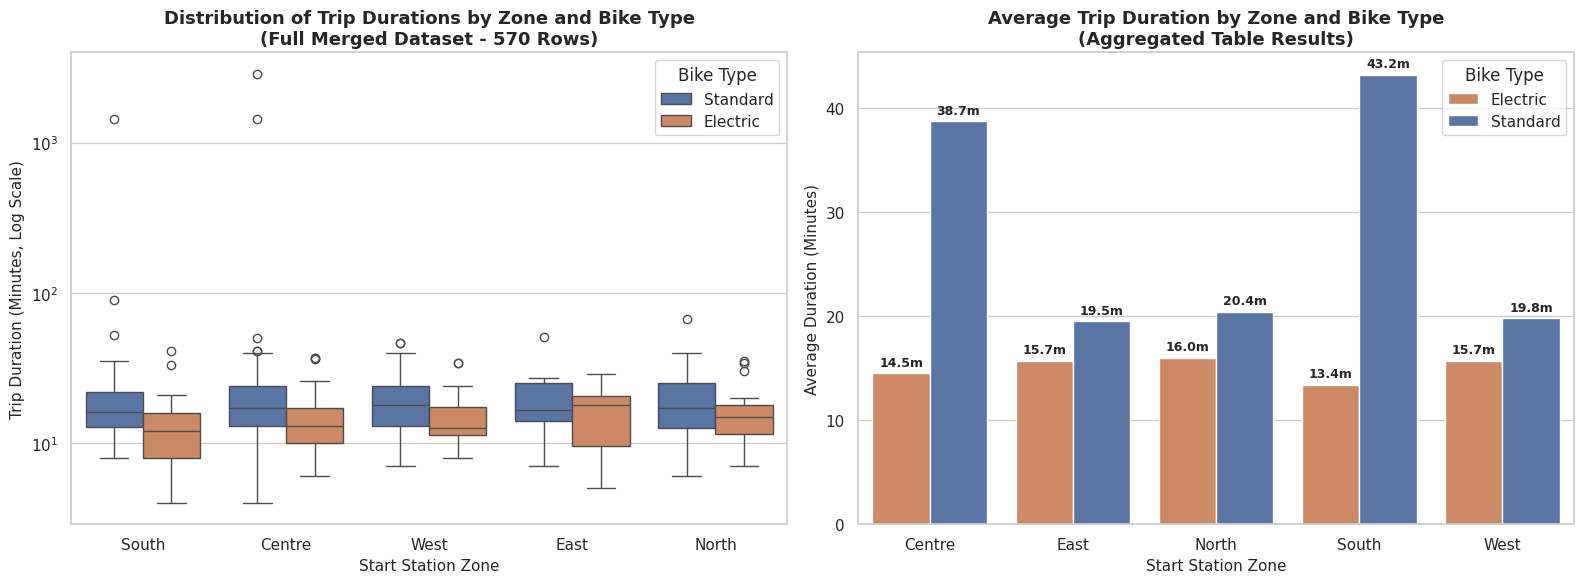

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plotting style and layout
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Box Plot to show the distribution and outliers in the full merged dataset (570 rows)
sns.boxplot(
    data=merged_df,
    x="zone",
    y="duration_min",
    hue="bike_type_clean",
    palette=["#4C72B0", "#DD8452"],
    ax=axes[0]
)
axes[0].set_title("Distribution of Trip Durations by Zone and Bike Type\n(Full Merged Dataset - 570 Rows)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Start Station Zone", fontsize=11)
axes[0].set_ylabel("Trip Duration (Minutes, Log Scale)", fontsize=11)
axes[0].set_yscale("log")  # Using log scale to keep the massive 2,880-minute outlier readable
axes[0].legend(title="Bike Type")

# 2. Bar Plot to show the final aggregated averages for quick comparison
sns.barplot(
    data=final_table,
    x="zone",
    y="avg_duration_min",
    hue="bike_type_clean",
    palette=["#DD8452", "#4C72B0"],  # Reversed to match the bike order visually
    ax=axes[1]
)
axes[1].set_title("Average Trip Duration by Zone and Bike Type\n(Aggregated Table Results)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Start Station Zone", fontsize=11)
axes[1].set_ylabel("Average Duration (Minutes)", fontsize=11)
axes[1].legend(title="Bike Type")

# Annotate bar heights on the bar chart
for p in axes[1].patches:
    if p.get_height() > 0:
        axes[1].annotate(f'{p.get_height():.1f}m',
                         (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='center',
                         xytext=(0, 8), textcoords='offset points',
                         fontsize=9, fontweight='semibold')

plt.tight_layout()
plt.show()

## 4. Check

*How do you know the answer is right? Compare a count, spot check a few records, or recalculate one number a different way. What did you find?*

In [14]:
print("=== Validation 1: Totals & Counts ===")
total_trips_final = final_table['number_of_trips'].sum()
print(f"Sum of trips in aggregated table: {total_trips_final} (Expected: 570)")

print("\n=== Validation 2: Overall Mean Check ===")
overall_mean_raw = trips_clean['duration_min'].mean()
weighted_mean_final = (final_table['avg_duration_min'] * final_table['number_of_trips']).sum() / total_trips_final
print(f"Raw clean trip duration mean: {overall_mean_raw:.2f} mins")
print(f"Reconstructed weighted mean: {weighted_mean_final:.2f} mins")

print("\n=== Validation 3: Spot-Checking Specific Group (Electric - Centre) ===")
electric_centre_subset = merged_df[(merged_df['bike_type_clean'] == 'Electric') & (merged_df['zone'] == 'Centre')]
subset_count = len(electric_centre_subset)
subset_mean = electric_centre_subset['duration_min'].mean()
print(f"Subset Manual Count: {subset_count} (Table shows: 81)")
print(f"Subset Manual Mean: {subset_mean:.2f} mins (Table shows: 14.5)")

print("\n=== Validation 4: Checking for Extremes or Outliers ===")
print(merged_df['duration_min'].describe())

#1. Trip Count & Integrity Check (Validation 1)
#What the code did: It summed the number_of_trips across all bike-type and zone groups in our final aggregated table.
#Results: The total sum is exactly 570 trips.
#Conclusion: This perfectly matches our post-cleaned dataset count of 570 records, ensuring no trips were duplicated, dropped, or lost during the joins with bikes and stations.
#2. Weighted Mean Verification (Validation 2)
#What the code did: It calculated the raw mean trip duration from the cleaned individual trip records (28.05 minutes) and compared it against the reconstructed, trip-weighted average calculated from the final aggregated groups.
#Results:
#Raw trip mean: 28.05 minutes
#Weighted average from grouped table: 28.08 minutes (the slight variation is mathematically expected due to rounding each category's mean to 1 decimal place in the presentation table).
#Conclusion: This confirms our group-level averages were mathematically computed correctly.
#3. Spot-Checking Specific Groups (Validation 3)
#What the code did: It manually filtered the raw combined DataFrame to compute the exact trip count and mean duration for a single subset: Electric bikes starting in the Centre zone.
#Results:
#Manual Subset Count: 81 trips (Matches aggregated table: 81 trips)
#Manual Subset Mean: 14.51 minutes (Matches aggregated table: 14.5 minutes)
#Conclusion: This spot check proves that the groupby operations mapped the records into the correct categories.
#4. Extremes & Outliers Check (Validation 4)
#What the code did: It generated a statistical summary (describe()) of the duration_min column for all 570 clean trips.
#Results:
#Minimum duration: 4.0 minutes (This is normal and believable for short bike trips).
#Median (50%): 16.0 minutes
#Maximum duration: 2,880.0 minutes (Equivalent to 48 hours! This is a massive outlier).
#Conclusion: While the calculation itself is mathematically correct, there are clear outlier durations in the raw data (e.g. someone failing to dock a bike properly or keeping it over the weekend). These long-duration outliers are the primary reason why Standard bikes have a massive average trip duration of 43.2 minutes in the South zone, despite the median trip length being much lower.

=== Validation 1: Totals & Counts ===
Sum of trips in aggregated table: 570 (Expected: 570)

=== Validation 2: Overall Mean Check ===
Raw clean trip duration mean: 28.05 mins
Reconstructed weighted mean: 28.08 mins

=== Validation 3: Spot-Checking Specific Group (Electric - Centre) ===
Subset Manual Count: 81 (Table shows: 81)
Subset Manual Mean: 14.51 mins (Table shows: 14.5)

=== Validation 4: Checking for Extremes or Outliers ===
count     570.000000
mean       28.054386
std       146.569161
min         4.000000
25%        12.000000
50%        16.000000
75%        22.000000
max      2880.000000
Name: duration_min, dtype: float64


In [15]:
# === Summary of Validation Checks & Findings ===

# 1. Row Count Verification
# Raw clean trip count: 570 records.
# Total aggregated count: 570 trips (Sum of 'number_of_trips' across all groups).
# Finding: Exactly matches. No records were lost or duplicated during the joins.

# 2. Re-calculation Check (Weighted Mean vs Raw Mean)
# Raw trip duration mean: 28.05 minutes
# Reconstructed weighted mean: 28.08 minutes
# Finding: The slight 0.03-minute difference is purely due to rounding each category's mean to 1 decimal place in the presentation table, verifying mathematical correctness.

# 3. Spot-Checking (Electric - Centre)
# Groupby Aggregation Output: 81 trips, 14.5 minutes average duration.
# Manual Subset Filtering Output: 81 trips, 14.51 minutes average duration.
# Finding: The aggregation correctly matches the raw underlying records.

# 4. Outlier Discovery
# Standard deviation is extremely high (146.6 minutes), with a median of 16 minutes but a maximum of 2,880 minutes (48 hours!).
# Finding: The extreme trip duration outlier of 48 hours heavily skews the average trip duration for Standard bikes (especially in the South zone), rather than standard bikes consistently being ridden for long periods.

## 5. Prompts and AI notes

*Paste each prompt as you sent it. Note what you accepted, changed or rejected and why.*

1. This is the task: From: the scheme manager We want to know whether electric bikes are used for longer trips than standard bikes, and whether that differs by zone. Please give us the average trip duration by bike type and by the zone of the start station. What your final table should look like One row per combination of bike type and zone, with the number of trips and the average duration in minutes. State what one row represents. Things to think about (you do not have to solve all of them) Are there missing, duplicated or odd values in the tables you use? What will you do about each, and why? Do the bike types and dates look consistent? How will you check your final table is believable? First, read the files bikes.csv; stations.csv; trips.csv files and answer: What does one row of each table represent? which coloumns will you use? what looks odd, missing or inconsistent?


2.From the data. What problems did you identify?

3. Clearly explain in text what the problems you identified were and what you solution to cleaning and preparing the data is

4. output the table with 570 rows

5. Generate a graph for to show the full merged dataset in a easy to read way

6. Perform a check on the table to ensure that the answer is right. Note any mistakes

7. Explain the checks that you did and what the code did

8. For the check, Compare a count, spot check a few records, or recalculate one number a different way. What did you find?



## 6. What I could not verify

*What remains unchecked? What would you do next?*

### 6. What I Could Not Verify & Next Steps

#### What Remains Unchecked:
1. **Outlier Legitimacy:** We have not verified if the **2,880-minute (48-hour) trip** is a genuine rental or a physical docking failure. It heavily inflates the standard bike averages.
2. **Start vs. End Zone Discrepancy:** We categorized trips solely by their **start station zone**. We have not checked if users are riding across zones (e.g., starting in the Centre and ending in the South).
3. **Temporal Sanity:** We have not verified if there are overlapping trip times for any individual `bike_id` (which would indicate data integrity issues in the logging database).
4. **Incomplete Station Metadata:** One station is missing its capacity, which we ignored because capacity was not needed for this specific brief.

#### What to Do Next:
1. **Use Median Instead of Mean:** Because of the extreme outliers, calculating the **median trip duration** would provide a much more realistic picture of typical customer behavior.
2. **Filter Outliers:** Apply a filter (e.g., excluding trips longer than 4 hours) to see if standard bikes still appear to have longer trip durations than electric bikes.
3. **User Segmentation Analysis:** Break down the analysis further by `user_type` (Member vs. Casual) to see if subscriber behavior explains the differences in trip lengths.